## Tutorial: modelling dispersion on a DNA-inspired $\pi$-stacking system with Kvantify-SqDRIFT

In this tutorial, we estimate the energy of the same $\pi$-stacked system as in the [BEAST-VQE $\pi$-stacking tutorial](pi_stacking_beast_tutorial.ipynb), but now with Kvantify-SqDRIFT, a sample-based quantum diagonalization algorithm. We compute the energy along a scan of the distance between the stacked fragments, from the equilibrium geometry to the dissociated limit, and use it to estimate the binding energy of the stacked dimer. The quantum chemistry problem is built with projective embedding, and the quantum circuits are simulated with Kvantify's memory-restricted simulator.

<div align="center"><img src="images/pi_stacking_image.png" alt="Thymine dimer extracted from the DNA atomistic model PDB 208D" width="450"></div>

**Why is this interesting?** The stacking of neighbouring nucleobases helps stabilize the DNA double helix. Dispersion, which arises from electron correlation, is an important contribution, alongside electrostatics and other interactions. The weak binding in the model studied here (about 1 kcal/mol) tests correlated methods: Hartree-Fock and uncorrected B3LYP miss the long-range dispersion contribution.

Kvantify-SqDRIFT belongs to the family of quantum-selected configuration interaction (QSCI) methods. Instead of variationally optimizing a parametrized circuit, the quantum computer is used to sample electronic configurations (Slater determinants) from a set of Krylov states, $e^{-i k \tau H}|\Phi_0\rangle$, prepared with randomized qDRIFT time-evolution circuits. The Hamiltonian is then diagonalized classically in the subspace spanned by the sampled determinants. The algorithm periodically updates the qDRIFT term-sampling distribution, and optionally the reference state, from the determinants found so far, so that the circuits are steered towards the important parts of the Hilbert space. See the [SqDRIFT explanation](https://qrunch.docs.kvantify.net/docs/explanations/sqdrift.html) in the documentation for the background.

**What you will learn:**
- how to reuse the embedded problems built (and persisted) by the other $\pi$-stacking tutorials;
- how to set up and run Kvantify-SqDRIFT on a memory-restricted simulator, and what its main knobs do;
- how to turn the results into a binding curve, assess the role of electron correlation in this model, and compare it with BEAST-VQE.

This notebook is one of a series of $\pi$-stacking tutorials living in the same folder: the [BEAST-VQE tutorial](pi_stacking_beast_tutorial.ipynb), this Kvantify-SqDRIFT tutorial, and the [quantum phase estimation (QPE) tutorial](pi_stacking_qpe_tutorial.ipynb). They all build exactly the same embedded problems and share the persisted problem files, so the expensive embedding and active space step is only done once, by whichever notebook is run first.

All of the classes and methods we need will be found in the `qrunch` package. The documentation for the Kvantify Qrunch can be found [here](https://qrunch.docs.kvantify.net/index.html). We also define the folders where files will be stored, and set up the logger, which allows us to keep track of basic information when running the algorithms.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import qrunch as qc

result_path = Path("results")
result_path.mkdir(exist_ok=True, parents=True)

output_path = Path("output")
output_path.mkdir(exist_ok=True, parents=True)

qc.setup_logger(qc.LOGGER_INFO)

## Requirements and hardware

- **Qrunch:** install `qrunch` following the [installation guide](https://qrunch.docs.kvantify.net/docs/getting_started.html).
- **License:** a [Qrunch Pro license](https://qrunch.docs.kvantify.net/docs/getting_started.html#register-a-license) is required for Kvantify-SqDRIFT.
- **Additional package:** `matplotlib` for plotting.
- **Hardware:** 16 GB RAM and a multicore CPU recommended; no GPU required. Allow more RAM for the optional CASCI reference.
- **Runtime:** initial embedding takes about an hour on a laptop. Simulation cost depends on the circuit budget and retained determinants.
- **Storage:** persisted chemistry data in `output` are shared across the three tutorials; energies are saved in `results`.

### Setting up the experiment

The starting point is an .xyz file containing the 17 points of the scan. For the sake of execution time, we only use 7 of them: two points on the repulsive side, the minimum (scan point 2), three points on the attractive side and the dissociated limit (scan point 16). This subselection is the reason for a bit more complicated code in the experiment setup - otherwise we would just pass the xyz file name to `qc.build_reaction_configuration`.

This problem definition is shared across the different pi-stacking tutorials, and running it once will therefore speed up the execution of the other tutorials as well. Building the problem takes about 1h on a standard laptop. The choices are explained in more detail in the [BEAST-VQE tutorial](pi_stacking_beast_tutorial.ipynb); keep them identical across the tutorials, otherwise the persisted problems are not reused.

In [2]:
reaction_path = Path("submodel_dt6dt7_scan.xyz")
# Normally we would use the reaction_path directly in the build_reaction_configuration step, but here we select specific geometries for the 17-point scan; 2 is the minimum, 16 the dissociated limit.
selected_geometries = [0, 1, 2, 4, 6, 9, 16]

def read_xyz_frames(xyz_path: Path) -> list[list[tuple[str, float, float, float]]]:
    """Return the atoms (element, x, y, z) of every frame of a multi-frame .xyz file."""
    lines = xyz_path.read_text().strip().splitlines()
    number_of_atoms = int(lines[0])
    frames = []
    for start in range(0, len(lines), number_of_atoms + 2):
        atom_lines = lines[start + 2 : start + 2 + number_of_atoms]
        frames.append([(element, float(x), float(y), float(z)) for element, x, y, z in map(str.split, atom_lines)])
    return frames

scan_frames = read_xyz_frames(reaction_path)
reaction = [scan_frames[index] for index in selected_geometries]
print(f"Selected scan points {selected_geometries} out of {len(scan_frames)}")

Selected scan points [0, 1, 2, 4, 6, 9, 16] out of 17


Now we build our reaction configuration using [projective embedding theory](https://qrunch.docs.kvantify.net/docs/explanations/projective_embedding.html). To focus the correlated calculation on the stacking region, we treat the embedded region with Kvantify-SqDRIFT and retain a classical DFT environment. This reduces the quantum problem without discarding the surrounding molecular framework. We specify the embedded atoms, spin difference (number of alpha minus beta electrons), charge and a modest basis set for manageable run times.

The embedded region consists of the two thymine rings, their carbonyl oxygens and ring-bound hydrogens, where we focus the treatment of electron correlation. The methyl groups and sugar-backbone stubs remain in the DFT environment.

In [3]:
bset = "6-31+g"
# Embedded atoms (0-based) of each thymine: ring atoms, carbonyl oxygens and the H atoms on N3 and C6.
ring1 = [2, 3, 4, 5, 6, 7, 8, 10, 24, 25]
ring2 = [12, 13, 14, 15, 16, 17, 18, 20, 27, 28]
embedded_atoms = ring1 + ring2
charge = 0
spin = 0

reaction_config = qc.build_reaction_configuration(
    reaction=reaction,
    basis_set=bset,
    charge=charge,
    spin_difference=spin,
    embedded_atoms=embedded_atoms,
)

### Creating the problem with the problem builder

We use the [fluent build pattern](https://qrunch.docs.kvantify.net/docs/explanations/builder_pattern.html) to construct a `problem_builder_creator`. As in the BEAST-VQE tutorial, we calculate along a `reaction_path` with the `even_handed` approach, so that the active orbital assignment is consistent across all frames of the scan. This is crucial for a smooth potential energy surface.

Before going into details here, let us define a couple of parameters that are required for the quantum calculation and which we may want to play with later, specifically:
- the active space: 16 spatial orbitals with 5 alpha (and 5 beta) electrons. Unlike BEAST-VQE, which only describes paired electrons, Kvantify-SqDRIFT works with the full fermionic wave function, so each spin orbital becomes a qubit and the circuits act on 32 qubits;
- the Kvantify-SqDRIFT parameters, which are discussed below when the calculator is set up.

In [4]:
# (16 spatial orbitals, 10 electrons) active space: 32 spin orbitals, i.e. 32 qubits for Kvantify-SqDRIFT.
active_orbitals = 16
active_alpha_electrons = 5

maximum_krylov_order = 3
number_of_randomizations = 4096
subsequence_length = 64
shots_per_circuit = 128
update_frequency = 2048
pruning_threshold = 4e-5
max_number_of_amplitudes = 100_000

The choices for the following cell, where we run the fluent builder pattern are:
- a DFT (B3LYP) full-system mean-field calculation;
- an orbital assignment based on the total weight of the atomic orbital contributions;
- MP2 natural orbitals for the embedded region (with a truncation of the virtual space);
- resolution of the identity for the full two-electron repulsion integrals;
- the active space defined above, followed by a conversion to dense integrals (which only happens in the active space).

**Important:** to reuse the orbitals and MP2 calculations that were already performed, every option that determines the stored data (functional, basis set, assignment tolerance, MP2 threshold, auxiliary basis, active space, ...) must be identical to the ones used in the earlier run.

In [5]:
dft_options = qc.options.DftCalculatorOptions(functional="b3lyp")
mp2_options = qc.options.MollerPlesset2CalculatorOptions(virtual_truncation_threshold=1e-6)

persister_path = output_path / "persister_data"
persister_path.mkdir(exist_ok=True, parents=True)

reaction_builder_creator = (
    qc.problem_builder_creator()
    .reaction_path()
    .even_handed()
    .choose_full_system_solver()
    .dft(dft_options)
    .choose_orbital_assigner()
    .total_weight(assignment_tolerance=0.3)
    .choose_embedded_orbital_calculator()
    .moller_plesset_2(mp2_options)
    .choose_repulsion_integral_builder()
    .resolution_of_the_identity(auxiliary_basis="heavy-aug-cc-pvdz-ri")
    .add_problem_modifier()
    .active_space(active_orbitals, active_alpha_electrons)
    .add_problem_modifier()
    .to_dense_integrals()
)

When running calculations on embedded systems, it is useful to store the mean-field results and orbital assignment details so that they can be reused. This is the role of the `data_persister_manager`. We point it to the persister folder shared by all the $\pi$-stacking tutorials, and use `load_policy="fallback"`: the stored files are loaded when present, and generated only if they are missing.

In [6]:
reaction_builder_creator = (
    reaction_builder_creator.choose_data_persister_manager().file_persister(
        directory=persister_path,
        extension=".qdk",
        load_policy="fallback",
        overwriting_policy="overwrite",
    )
)

reaction_builder = reaction_builder_creator.create()

We now build the even-handed reaction path problem for the selected scan points. If the persisted files are already in place, for instance because one of the other $\pi$-stacking tutorials has been run, this step only loads them (check the log: it should not start new DFT or MP2 calculations). Without existing checkpoint files (the first time this is run) the following cell takes about 1h to finish.

In [7]:
reaction_problem = reaction_builder.build_restricted(reaction_config)
print(f"Built {len(reaction_problem.ground_state_problems)} problems for scan points {selected_geometries}")

2026-11-24 05:43:14 [INFO] (kvantify.qrunch): Embedded atoms: [
    N: (9.359, 20.621, 2.68),
    C: (8.607, 19.479, 2.529),
    O: (7.436, 19.482, 2.212),
    N: (9.207, 18.286, 2.75),
    C: (10.496, 18.116, 3.111),
    O: (10.914, 16.977, 3.256),
    C: (11.24, 19.351, 3.252),
    C: (10.662, 20.544, 3.038),
    H: (8.644, 17.45535, 2.63535),
    H: (11.24096, 21.4485, 3.15236),
    N: (5.82, 20.104, 5.63),
    C: (5.875, 18.704, 5.589),
    O: (4.924, 18.004, 5.282),
    N: (7.065, 18.102, 5.901),
    C: (8.223, 18.748, 6.252),
    O: (9.251, 18.092, 6.395),
    C: (8.112, 20.206, 6.301),
    C: (6.933, 20.839, 5.991),
    H: (7.0923, 17.09285, 5.86987),
    H: (6.87564, 21.91678, 6.02962),
]
2026-11-24 05:43:14 [INFO] (kvantify.qrunch): Embedded atoms: [
    N: (9.359, 20.621, 2.68),
    C: (8.607, 19.479, 2.529),
    O: (7.436, 19.482, 2.212),
    N: (9.207, 18.286, 2.75),
    C: (10.496, 18.116, 3.111),
    O: (10.914, 16.977, 3.256),
    C: (11.24, 19.351, 3.252),
    C: (10.66

KeyboardInterrupt: 

### Running the quantum algorithm

Kvantify-SqDRIFT only needs a `sampler`: the energy is obtained by classical diagonalization in the sampled subspace, so no `estimator` is required. We use the `memory_restricted` simulator. Since the qDRIFT time-evolution circuits produce complex amplitudes, we switch off `use_real_numbers`. We keep at most `max_number_of_amplitudes` amplitudes, and prune amplitudes with a norm below `amplitude_cutoff`; tiny amplitudes are essentially never sampled anyway.

In [ ]:
sampler_options = qc.options.MemoryRestrictedSimulatorOptions(
    suppress_warnings=True,
    use_real_numbers=False,
    max_number_of_amplitudes=max_number_of_amplitudes,
)
sampler = qc.sampler_creator().memory_restricted().with_options(sampler_options).create()

/home/pe/Software/miniconda3/envs/qrunch-2.0.0dev1/lib/python3.12/importlib/__init__.py:90: UserWarning: The module 'qrunch.core.license.license' is not part of the public API of 'qrunch'. Its interface may change without notice.
The module was imported from importlib.
  return _bootstrap._gcd_import(name[level:], package, level)


Next we set the SqDRIFT options, which define the circuits:
- `maximum_krylov_order`: circuits are generated for every Krylov order $k = 1, \ldots, d$;
- `number_of_randomizations`: the number of independent qDRIFT circuits per Krylov order;
- `subsequence_length`: the number of Hamiltonian terms sampled into each qDRIFT circuit, i.e. its depth in terms of excitation gates.

In total, `maximum_krylov_order * number_of_randomizations` circuits are sampled, each with `shots_per_circuit` shots. A seed makes the randomized circuits reproducible.

In [ ]:
sqdrift_options = qc.options.SqDriftOptions(
    subsequence_length=subsequence_length,
    maximum_krylov_order=maximum_krylov_order,
    number_of_randomizations=number_of_randomizations,
    seed=42,
)

Kvantify-SqDRIFT can encode the current subspace ground state in the reference state from which the Krylov circuits start. This improves the accuracy at the cost of deeper circuits. The encoding circuit is found with a beam search over excitation operators; `max_operators` bounds the number of operators, and thus the depth of the state preparation.

In [ ]:
state_encoding_options = qc.options.FixedParticleNumberStatePrepBeamSearchOptions(
    beam_width=3,
    max_operators=8,
    max_number_of_amplitudes=max_number_of_amplitudes,
)

With those elements, we set up the calculator using a `calculator_creator`. Every `update_frequency` circuits, the sampling strategy is updated: the subspace is diagonalized, the qDRIFT term-sampling distribution is reweighted, and the reference state is re-encoded. At each update, determinants whose configuration-interaction coefficient falls below `pruning_threshold` are removed from the subspace, which keeps the classical diagonalization cheap.

In [ ]:
calculator = (
    qc.calculator_creator()
    .quantum_selected_configuration_interaction()
    .sharp_sqdrift()
    .with_sampler(sampler)
    .with_shots_per_circuit(shots_per_circuit)
    .with_sqdrift_options(sqdrift_options)
    .with_update_frequency(update_frequency)
    .with_state_encoding_options(state_encoding_options)
    .with_pruning_options("Coefficient", pruning_threshold=pruning_threshold)
    .create()
)

Now the chemistry definitions and the quantum algorithm come together. We run the calculator on our reaction problem; it performs a Kvantify-SqDRIFT calculation for each of the selected geometries. The `results` object will contain the information on the energies.

This is the longest step after the problem building, so it is a good moment for a coffee. While you wait, try to guess whether Kvantify-SqDRIFT will find a deeper or a shallower minimum than BEAST-VQE.

In [ ]:
results = calculator.calculate(reaction_problem)

2026-11-18 06:21:32 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 37/100000 amplitudes, and the state vector simulation was exact.
2026-11-18 06:21:32 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 1/100000 amplitudes, and the state vector simulation was exact.
2026-11-18 06:21:32 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 12/100000 amplitudes, and the state vector simulation was exact.
2026-11-18 06:21:32 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 1/100000 amplitudes, and the state vector simulation was exact.
2026-11-18 06:21:32 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 14/100000 amplitudes, and the state vector simulation was exact.
2026-11-18 06:21:32 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 1/100000 amplitudes, and the state vector simulation was exact.
2026-11-18 06:21:32 [INFO] (kva

### Extracting results

We can now look at the energies found across the selected geometries. To plot the energy profile against a physical coordinate, we use the ring-ring separation of each geometry, defined as the distance between the centroids of the two thymine rings (atoms N1, C2, N3, C4, C5, C6 of each monomer). Since the rings are slipped with respect to each other, this distance is larger than the interplanar distance. The separations have been precomputed for all 17 points of the scan, and we pick those of the selected geometries:

In [ ]:
# Ring centroid-centroid distance (Å) of each of the 17 points in submodel_dt6dt7_scan.xyz.
ring_ring_separation = [
    4.226, 4.682, 5.145, 5.616, 6.090, 6.569, 7.051, 7.534, 8.020,
    8.508, 8.997, 9.487, 9.978, 10.470, 10.963, 11.456, 11.950,
]

separations = [ring_ring_separation[index] for index in selected_geometries]

The final total energy of each geometry is collected from the results and plotted against the ring-ring separation. The energy should decrease from the repulsive side to the minimum, and then rise slowly towards the dissociated limit, the difference between the two being the (small) binding energy of the stacked dimer.

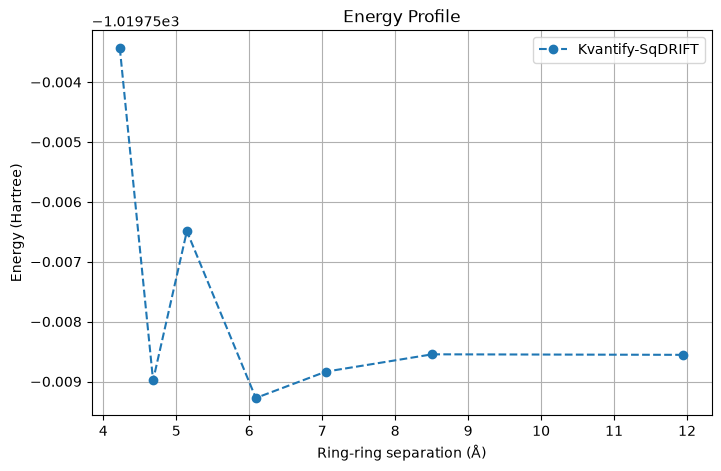

In [ ]:
final_reaction_energies = results.total_energies.values

plt.figure(figsize=(8, 5))
plt.plot(separations, final_reaction_energies, marker="o", linestyle="--", label="Kvantify-SqDRIFT")
plt.xlabel("Ring-ring separation (Å)")
plt.ylabel("Energy (Hartree)")
plt.title("Energy Profile")
plt.legend()
plt.grid()
plt.show()

### Classical reference calculations

To judge the quantum results, we compare them with two well-established classical methods, applied to the same embedded active space:
- CASCI (complete active space configuration interaction) solves the active space problem exactly. Its cost grows exponentially with the size of the active space; with 16 orbitals and 10 electrons there are about 19 million determinants, which is still feasible on a laptop, but it takes a while. Note that Kvantify-SqDRIFT is a selected configuration interaction method: it approximates the CASCI solution with a much smaller subspace of determinants.
- CCSD(T) (coupled cluster with singles, doubles and perturbative triples), the "gold standard" of quantum chemistry for weakly correlated systems such as this one. Its cost grows polynomially, so it remains feasible for much larger active spaces, where CASCI is out of reach.

The reference energies are the same for all the $\pi$-stacking tutorials, so they are stored in the `results` folder and only computed by whichever tutorial runs first.

In [ ]:
classical_result_file = result_path / f"pi_stacking_classical_{active_orbitals}o.json"
classical_data = json.loads(classical_result_file.read_text()) if classical_result_file.exists() else {}

if classical_data.get("geometry_indices") != selected_geometries:
    classical_calculators = {"CCSD(T)": qc.calculator_creator().coupled_cluster().ccsd_t().create()}
    # CASCI scales exponentially with the active space size; beyond about 16 orbitals rely on CCSD(T) only.
    if active_orbitals <= 16:
        classical_calculators["CASCI"] = qc.calculator_creator().configuration_interaction().standard().create()
    classical_data = {"geometry_indices": selected_geometries}
    for label, calculator in classical_calculators.items():
        classical_data[label] = [float(e) for e in calculator.calculate(reaction_problem).total_energies.values]
    classical_result_file.write_text(json.dumps(classical_data, indent=2))

classical_energies = {label: values for label, values in classical_data.items() if label != "geometry_indices"}

The total energies are large numbers, while the interesting physics happens in the last few decimals. It is therefore more convenient to look at the energy relative to the dissociated limit, in kcal/mol: the depth of the minimum is the binding energy of the stacked dimer.

**Where does the binding come from?** The initial energy of each Kvantify-SqDRIFT run is the energy of the Hartree-Fock reference, i.e. a mean-field description of the active space. Comparing it with the final Kvantify-SqDRIFT energy tells us how much of the binding is due to electron correlation, and the classical CASCI and CCSD(T) curves show what we should aim for. If the [BEAST-VQE](pi_stacking_beast_tutorial.ipynb) or [QPE](pi_stacking_qpe_tutorial.ipynb) tutorials have been run, their results are loaded from the `results` folder and added to the plot. Make a guess before running the cell!

            Reference (Hartree-Fock): binding energy = 0.00 kcal/mol
                    Kvantify-SqDRIFT: binding energy = -0.45 kcal/mol
                             CCSD(T): binding energy = -0.77 kcal/mol
                               CASCI: binding energy = -0.77 kcal/mol
 OO-BEAST-VQE + PT2 (BEAST tutorial): binding energy = -1.04 kcal/mol
                 BQPE (QPE tutorial): binding energy = -1.12 kcal/mol


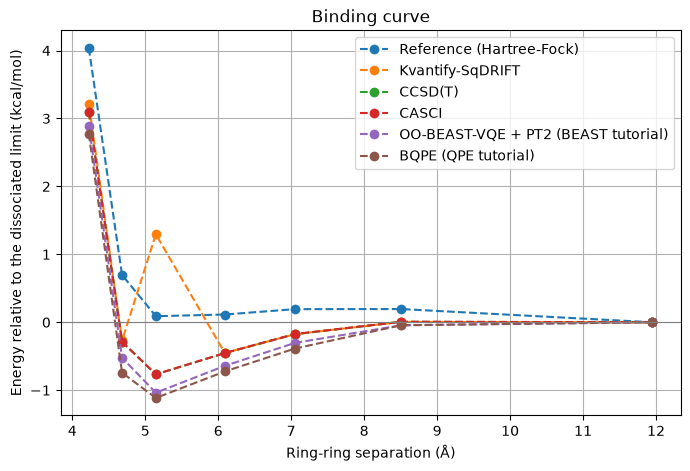

In [ ]:
hartree_to_kcal_per_mol = 627.5095

reference_energies = results.initial_total_energies.values

profiles = {
    "Reference (Hartree-Fock)": (selected_geometries, reference_energies),
    "Kvantify-SqDRIFT": (selected_geometries, final_reaction_energies),
}
for label, energies in classical_energies.items():
    profiles[label] = (selected_geometries, energies)

other_tutorials = {
    "OO-BEAST-VQE + PT2 (BEAST tutorial)": f"pi_stacking_beast_{active_orbitals}o.json",
    "BQPE (QPE tutorial)": f"pi_stacking_qpe_{active_orbitals}o.json",
}
for label, file_name in other_tutorials.items():
    if (result_path / file_name).exists():
        data = json.loads((result_path / file_name).read_text())
        profiles[label] = (data["geometry_indices"], [energy["value"] for energy in data["total_energy_per_geometry"]])

plt.figure(figsize=(8, 5))
for label, (scan_points, energies) in profiles.items():
    # The last scan point is the dissociated limit.
    relative_energies = [(energy - energies[-1]) * hartree_to_kcal_per_mol for energy in energies]
    plt.plot([ring_ring_separation[point] for point in scan_points], relative_energies, marker="o", linestyle="--", label=label)
    print(f"{label:>36s}: binding energy = {min(relative_energies):.2f} kcal/mol")
plt.axhline(0.0, color="grey", linewidth=0.8)
plt.xlabel("Ring-ring separation (Å)")
plt.ylabel("Energy relative to the dissociated limit (kcal/mol)")
plt.title("Binding curve")
plt.legend()
plt.grid()
plt.show()

As in the BEAST-VQE tutorial, the Hartree-Fock reference shows (essentially) no binding: the stacking of the two thymines only appears once electron correlation is included. How close does Kvantify-SqDRIFT get to the CASCI curve, which is the exact solution in the same active space? And how close are the quantum algorithms to each other? Keep in mind that Kvantify-SqDRIFT works with all electrons of the active space, while BEAST-VQE describes paired electrons and adds the broken pairs perturbatively.

Finally, we save the results, together with the main parameters of the calculation, to a JSON file. The [BEAST-VQE tutorial](pi_stacking_beast_tutorial.ipynb) reads this file to add the Kvantify-SqDRIFT binding curve to its own plot.

In [ ]:
final_data = {
    "charge": charge,
    "spin": spin,
    "basis_set": str(bset),
    "embedded_atom_indices": embedded_atoms,
    "cas": {
        "number_of_active_spatial_orbitals": active_orbitals,
        "number_of_active_alpha_electrons": active_alpha_electrons,
    },
    "simulator": "memory_restricted",
    "max_number_of_amplitudes": max_number_of_amplitudes,
    "maximum_krylov_order": maximum_krylov_order,
    "number_of_randomizations": number_of_randomizations,
    "subsequence_length": subsequence_length,
    "shots_per_circuit": shots_per_circuit,
    "update_frequency": update_frequency,
    "pruning_threshold": pruning_threshold,
    "geometry_indices": selected_geometries,
    "total_energy_per_geometry": [{"value": float(e), "error": 0.0} for e in final_reaction_energies],
    "reference_energy_per_geometry": [{"value": float(e), "error": 0.0} for e in reference_energies],
    "nuclear_repulsion_per_geometry": results.nuclear_repulsions,
    "non_active_electrons_per_geometry": results.non_active_electrons_energies,
}

result_name = f"pi_stacking_sharp_sqdrift_{active_orbitals}o.json"
with open(result_path / result_name, "w") as f:
    json.dump(final_data, f, indent=2)
print(f"Saved results to {result_path / result_name}")

Saved results to results/pi_stacking_sharp_sqdrift_16o.json


### Now it's your turn

Some ideas to explore, roughly ordered by the time they take:
- **Compare with BEAST-VQE:** if you have not done so yet, run the [BEAST-VQE tutorial](pi_stacking_beast_tutorial.ipynb). It reuses the persisted problems, and once its results are saved, rerunning the binding-curve cell above shows both quantum algorithms in one plot.
- **Sampling statistics:** SqDRIFT is a stochastic algorithm - repeat the same experiment a couple of times with a different seed, plot the outcomes and perform some statistical analyses on the results.
- **Sampling budget:** increase `number_of_randomizations` or `maximum_krylov_order` and check how the energies and the binding energy converge, and how the runtime grows. To save time, try a single geometry first, e.g. `calculator.calculate(reaction_problem.ground_state_problems[2])`.
- **Circuit depth versus accuracy:** change `subsequence_length`, or call `.disable_state_encoding()` on the calculator creator to always start from the Hartree-Fock state.
- **Classical cost:** lower `pruning_threshold`, or use `"Pt2"` pruning, and look at the size of the subspace and the cost of the classical diagonalization.
- **Noise:** use a [noise model in the simulation of the sampler](https://qrunch.docs.kvantify.net/docs/guides/running_calculations/noisy_simulators.html). Since only the sampled determinants matter, how robust is Kvantify-SqDRIFT against noise compared to BEAST-VQE?
- **Real hardware:** move the sampler [to actual quantum hardware](https://qrunch.docs.kvantify.net/docs/guides/running_calculations/using_quantum_computers.html). Start with a single geometry and a small number of randomizations.
- **Different scan points:** editing `selected_geometries` changes the problem definition: the problems are built (and persisted) from scratch, which takes about an hour, and they will no longer match the ones used in the other $\pi$-stacking tutorials.